# 02 · One-stage anchor-free detector: YOLOv8

Covers the *One-stage Anchor-free* checkpoint and produces the **first leaderboard submission**.

**Fixed protocol** (identical for every detector in this project):
* train: official `train` clips, every 5th frame (4 868 frames), ignored regions masked (see 01, §4.2)
* evaluation: all 2 846 frames of the 7 official `val` clips, original resolution, our evaluator from `vdet.evaluate`
  (ignored regions = crowd, maxDets 500). Ultralytics' own val numbers are only a training monitor.
* same number of epochs, seed 42, COCO-pretrained weights

**Experiments** (each changes one thing relative to the previous one):

| id | change | motivation from EDA |
|---|---|---|
| E0 | YOLOv8s, imgsz 640, defaults | baseline |
| E1 | imgsz 1280 | at 640 px 54% of objects are < 16 px (§4.1) |
| E2 | + P2 head (stride 4) | adds a high-resolution level for the tiny objects |

A loss experiment (e.g. NWD instead of CIoU for tiny boxes) is added later on top of the best of these.

**Runtime:** Kaggle GPU (T4 or P100). Set `SMOKE = True` first to check that everything runs (~5 min),
then `SMOKE = False` and run it with *Save Version → Save & Run All* so training continues in the background.

## 1. Setup

In [1]:
# --- Environment detection and paths (same as notebook 01) -------------------------
import os, sys, glob, subprocess
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle/input")
COMPETITION = "multiple-object-video-detection-hw-2-ucu-ai-2026"   # Colab only: used to download the data

def find_repo():
    """Folder that contains the vdet/ package."""
    if IN_COLAB:  # anywhere on Google Drive
        for depth in range(0, 4):
            hits = sorted(glob.glob("/content/drive/MyDrive/" + "*/" * depth + "vdet/__init__.py"))
            if hits:
                return os.path.dirname(os.path.dirname(hits[0]))
        raise FileNotFoundError("vdet/ not found on Google Drive: upload the visdrone-det folder to MyDrive")
    if IN_KAGGLE:
        for depth in range(1, 6):
            hits = glob.glob("/kaggle/input/" + "*/" * depth + "vdet/__init__.py")
            if hits:
                return os.path.dirname(os.path.dirname(hits[0]))
        raise FileNotFoundError("vdet not found: add the code dataset via '+ Add Input'")
    return os.path.abspath("..")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    os.environ.setdefault("VDET_WORK", "/content/drive/MyDrive/visdrone-work")  # results survive disconnects
    if not os.path.exists("/content/data/train"):
        # Kaggle API token, never written into the notebook (it goes to GitHub):
        # Colab sidebar -> key icon (Secrets) -> name KAGGLE_API_TOKEN, value KGAT_..., notebook access ON.
        # Fallback: a legacy kaggle.json in the MyDrive root.
        from google.colab import userdata
        try:
            os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        except Exception:
            !mkdir -p /root/.kaggle && cp /content/drive/MyDrive/kaggle.json /root/.kaggle/ && chmod 600 /root/.kaggle/kaggle.json
        !pip -q install -U kaggle
        !kaggle competitions download -c {COMPETITION} -p /content -q
        !unzip -q -o /content/{COMPETITION}.zip -d /content/data && rm /content/{COMPETITION}.zip

# Ultralytics prints the model summary and a progress bar per epoch; keep the notebook output short.
# Per-epoch numbers are still saved to runs_yolo/<exp>/results.csv and plotted in section 4.
os.environ["YOLO_VERBOSE"] = "False"

for pkg, mod in [("pycocotools", "pycocotools"), ("ultralytics", "ultralytics")]:
    try:
        __import__(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

REPO_DIR = find_repo()
sys.path.insert(0, REPO_DIR)
print("repo:", REPO_DIR)

Mounted at /content/drive
repo: /content/drive/MyDrive/visdrone-det/visdrone-det


In [2]:
# --- Imports and configuration -------------------------------------------------------
import json, shutil, random
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import ultralytics
from ultralytics import YOLO

from vdet import CLASSES
from vdet import data as D, evaluate as E, submission as S, viz as V, yolo_export as YX, ultra as U
from vdet.paths import find_data_root, default_work_dir

SMOKE = False            # True: tiny run to test the pipeline. False: the real experiments.
RUN = ["E0", "E1", "E2"]  # experiments to run in this session (finished ones are skipped)

SEED = 42
EPOCHS = 2 if SMOKE else 25
BATCH = 8               # fits a 16 GB T4 at imgsz 1280 for YOLOv8s (P2 too); lower to 4 on OOM
TRAIN_STEP, VAL_MONITOR_STEP = 5, 3
EXPORT_SIDE = 1280      # frames are pre-resized to this longer side (= largest imgsz we train with)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DATA_ROOT = find_data_root()
WORK_DIR = default_work_dir()
TAG = "_smoke" if SMOKE else ""      # smoke runs never mix with the real ones
RUNS_DIR = WORK_DIR / f"runs_yolo{TAG}"
# exported frames (~3 GB): local disk, never Drive / saved output; rebuilt automatically after a disconnect
YOLO_DS = (Path("/tmp") if IN_KAGGLE else Path("/content") if IN_COLAB else WORK_DIR) / f"yolo_ds{TAG}"
FIG_DIR = WORK_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
log = U.ResultsLog(WORK_DIR / ("results_yolo_smoke.json" if SMOKE else "results_yolo.json"))

print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| device",
      torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")

ultralytics 8.4.198 | torch 2.11.0+cu130 | device Tesla T4


In [3]:
# --- Continue from a previous run (Kaggle sessions are limited to 12 h) ---------------
# On Colab nothing to do: runs_yolo/ is on Google Drive, so after a disconnect just Run All again,
# finished experiments are skipped and the interrupted one resumes from its last epoch.
# To continue: attach the output of a previous version of THIS notebook via "+ Add Input"
# (Your Work -> Notebooks) and put its path here. Finished runs are reused, unfinished ones resume.
PREV_OUTPUT = None   # e.g. "/kaggle/input/<this-notebook-name>"
if PREV_OUTPUT:
    for name in ("runs_yolo", "results_yolo.json"):
        src = Path(PREV_OUTPUT) / name
        if src.exists() and not (WORK_DIR / name).exists():
            (shutil.copytree if src.is_dir() else shutil.copy)(src, WORK_DIR / name)
    log = U.ResultsLog(WORK_DIR / "results_yolo.json")
    print("restored:", list(log.data))

## 2. Data: same selection as in notebook 01

In [4]:
tv = D.load_train_val(DATA_ROOT)
im = tv.images
train_keys = D.subsample_frames(im[im.split == "train"], TRAIN_STEP).key
monitor_keys = D.subsample_frames(im[im.split == "val"], VAL_MONITOR_STEP).key   # Ultralytics' per-epoch val
eval_keys = im[im.split == "val"].key                                             # our final numbers: all val frames
if SMOKE:   # a few frames per clip, just to exercise the code
    train_keys = D.subsample_frames(im[im.split == "train"], 200).key
    monitor_keys = eval_keys = D.subsample_frames(im[im.split == "val"], 100).key

train, monitor, val = tv.subset(train_keys), tv.subset(monitor_keys), tv.subset(eval_keys)
print("train:", train, "\nmonitor:", monitor, "\neval:", val)

train: SplitData(images=4868, boxes=222879, ignore=12898, clips=56) 
monitor: SplitData(images=951, boxes=38206, ignore=1338, clips=7) 
eval: SplitData(images=2846, boxes=114132, ignore=3995, clips=7)


In [5]:
# Export: masked + downscaled training frames, YOLO txt labels, data.yaml (one-off, ~5-10 min on Kaggle)
if not (YOLO_DS / "data.yaml").exists():
    stats = YX.export_yolo_dataset(train, monitor, YOLO_DS, mask_train=True, mask_val=False, max_side=EXPORT_SIDE)
    display(stats)
print((YOLO_DS / "data.yaml").read_text())

export train:   0%|          | 0/4868 [00:00<?, ?it/s]

export val:   0%|          | 0/951 [00:00<?, ?it/s]

,images,masked_images,boxes,dropped_boxes
train,4868,3644,220357,2522
val,951,0,38206,0


path: /tmp/yolo_ds
train: images/train
val: images/val
names:
  0: person
  1: bicycle
  2: car
  3: van
  4: truck
  5: tricycle
  6: bus
  7: motor



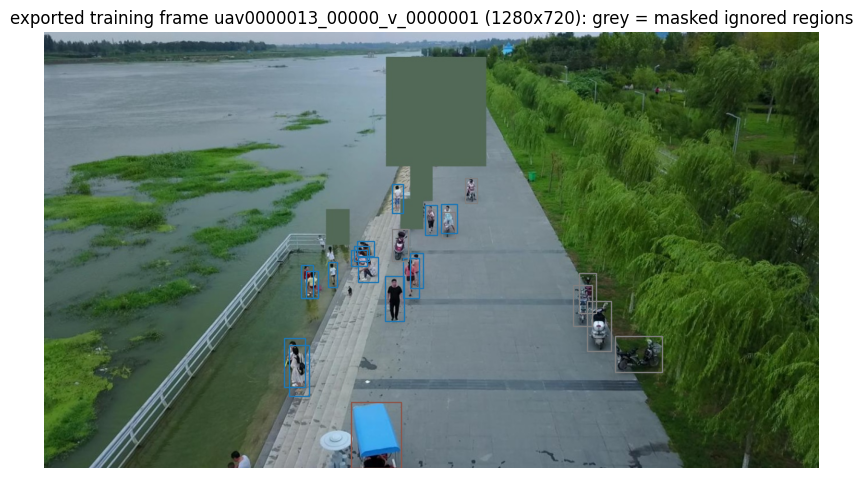

In [6]:
# Check the export: a masked training frame with its YOLO labels drawn back on it
import cv2
k = train.ignore.key.iloc[0] if len(train.ignore) else train.images.key.iloc[0]
img = cv2.cvtColor(cv2.imread(str(YOLO_DS / "images/train" / f"{k}.jpg")), cv2.COLOR_BGR2RGB)
H, W = img.shape[:2]
fig, ax = plt.subplots(figsize=(10, 6)); ax.imshow(img); ax.axis("off")
for line in (YOLO_DS / "labels/train" / f"{k}.txt").read_text().splitlines():
    c, cx, cy, w, h = map(float, line.split())
    ax.add_patch(plt.Rectangle(((cx - w / 2) * W, (cy - h / 2) * H), w * W, h * H, fill=False, ec=V.COLORS[int(c)], lw=1))
ax.set_title(f"exported training frame {k} ({W}x{H}): grey = masked ignored regions")
plt.show()

## 3. Experiments
Each experiment is a dict of Ultralytics arguments. `model` is either pretrained weights or a model
config. For the P2 config, COCO weights are copied only into layers whose position and shape still match:
Ultralytics reports ~219 of 437 tensors transferred (the backbone), while the reshaped neck and head start
from scratch. E2 is therefore at a disadvantage at an equal number of epochs; keep this in mind (and mention it)
when comparing E1 and E2.

In [7]:
COMMON = dict(epochs=EPOCHS, batch=BATCH, seed=SEED, deterministic=True, device=DEVICE, workers=4,
              optimizer="auto", cos_lr=False, close_mosaic=min(10, EPOCHS), patience=0,
              plots=True, val=True, verbose=False)

EXPERIMENTS = {
    "E0": dict(model="yolov8s.pt", imgsz=640),
    "E1": dict(model="yolov8s.pt", imgsz=1280),
    "E2": dict(model="yolov8s-p2.yaml", weights="yolov8s.pt", imgsz=1280),
}
if SMOKE:
    for e in EXPERIMENTS.values():
        e["imgsz"] = min(e["imgsz"], 320)
pd.DataFrame(EXPERIMENTS).T

,model,imgsz,weights
E0,yolov8s.pt,640,NaN
E1,yolov8s.pt,1280,NaN
E2,yolov8s-p2.yaml,1280,yolov8s.pt


In [8]:
def build_model(cfg):
    m = YOLO(cfg["model"])
    if "weights" in cfg:
        m = m.load(cfg["weights"])
    return m

def train_one(name):
    """Train (or resume) one experiment. Returns the path to best.pt."""
    cfg = EXPERIMENTS[name]
    run_dir = RUNS_DIR / name
    res_csv, last = run_dir / "results.csv", run_dir / "weights" / "last.pt"
    if res_csv.exists() and len(pd.read_csv(res_csv)) >= EPOCHS:
        print(f"{name}: already trained, skipping")
    elif last.exists():
        print(f"{name}: resuming from {last}")
        YOLO(str(last)).train(resume=True)
    else:
        args = {k: v for k, v in cfg.items() if k not in ("model", "weights")}
        build_model(cfg).train(data=str(YOLO_DS / "data.yaml"), project=str(RUNS_DIR), name=name,
                               exist_ok=True, **COMMON, **args)
    return run_dir / "weights" / "best.pt"

def evaluate_one(name, weights):
    """Predict all val frames at the original resolution and score them with OUR evaluator."""
    cfg = EXPERIMENTS[name]
    model = YOLO(str(weights))
    preds, sec = U.predict_table(model, val.images, imgsz=cfg["imgsz"], batch=BATCH,
                                 half=DEVICE == 0, desc=f"val {name}")
    preds.to_csv(RUNS_DIR / name / "val_preds.csv.gz", index=False)
    m = ev.evaluate(preds)
    m["ms_per_img"] = round(sec * 1000, 1)
    m["params_M"] = round(sum(p.numel() for p in model.model.parameters()) / 1e6, 2)
    log.add(name, cfg, m)
    return m

ev = E.DetectionEvaluator(val)

In [9]:
# --- Run the selected experiments (the long cell) ------------------------------------
for name in RUN:
    if name in log.data and not SMOKE:
        print(f"{name}: already evaluated"); continue
    best = train_one(name)
    m = evaluate_one(name, best)
    print(f"{name}: mAP {m['mAP']*100:.1f}  AP50 {m['AP50']*100:.1f}  AP_small {m['AP_small']*100:.1f}  "
          f"{m['ms_per_img']} ms/img")

E0: already evaluated
E1: already evaluated
E2: already trained, skipping


val E2:   0%|          | 0/356 [00:00<?, ?it/s]

E2: mAP 19.0  AP50 37.9  AP_small 10.3  65.6 ms/img


## 4. Results

In [10]:
res = log.table()
cols = ["mAP", "AP50", "AP75", "AP_tiny", "AP_small", "AP_medium", "AP_large", "AR500"]
show = res[cols].astype(float).mul(100).round(1).join(res[["ms_per_img", "params_M"]])
show

,mAP,AP50,AP75,AP_tiny,AP_small,AP_medium,AP_large,AR500,ms_per_img,params_M
E0,12.4,25.2,10.9,1.0,4.5,11.5,25.1,23.8,45.1,11.14
E1,19.8,39.3,17.6,1.6,12.7,18.9,31.6,32.3,55.2,11.14
E2,19.0,37.9,16.6,1.0,10.3,18.2,31.3,30.8,65.6,10.86


In [11]:
# Per-class AP: which classes does each change help?
pc = res[[f"AP_{c}" for c in CLASSES]].astype(float).mul(100).round(1)
pc.columns = CLASSES
pc

,person,bicycle,car,van,truck,tricycle,bus,motor
E0,20.7,5.2,31.3,8.5,6.9,12.7,5.7,8.3
E1,27.6,20.2,38.6,15.4,21.0,21.7,2.0,12.3
E2,27.1,15.8,39.8,15.9,16.6,21.8,3.0,12.1


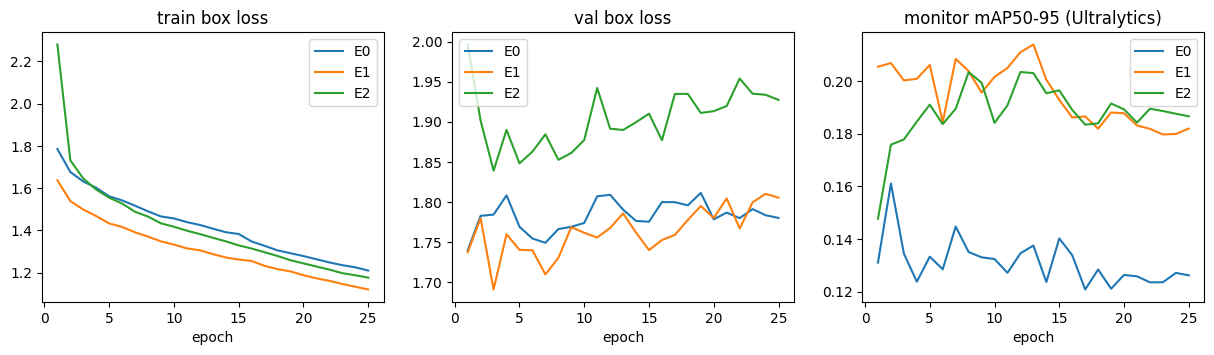

In [12]:
# Training curves. Note: Ultralytics' mAP is on the monitor subset (every 3rd val frame, no ignore handling)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for name in log.data:
    df = U.training_curve(RUNS_DIR / name)
    ax[0].plot(df["epoch"], df["train/box_loss"], label=name)
    ax[1].plot(df["epoch"], df["val/box_loss"], label=name)
    ax[2].plot(df["epoch"], df["metrics/mAP50-95(B)"], label=name)
for a, t in zip(ax, ["train box loss", "val box loss", "monitor mAP50-95 (Ultralytics)"]):
    a.set_title(t); a.set_xlabel("epoch"); a.legend()
fig.savefig(FIG_DIR / "yolo_curves.png", bbox_inches="tight"); plt.show()

> **Observation.** Resolution is the main factor: 640 → 1280 px (E0 → E1) gives +7.4 mAP (12.4 → 19.8) and AP_small 4.5 → 12.7;
> thin and small classes gain most (bicycle 5.2 → 20.2, truck 6.9 → 21.0). The P2 head (E2) did not help: 19.0 mAP,
> AP_small 10.3, and it is slower (65.6 vs 55.2 ms/img). Likely reasons: only 219 of 437 tensors get COCO weights, so
> the new neck and head start from scratch and 25 epochs are not enough; and val has only 0.4% objects below 16 px,
> the size P2 is made for. Curves: E1's monitor mAP is highest at epochs 7–13 (≈21%) and then drifts to ≈18% while the
> training loss keeps falling and the val box loss rises, i.e. mild overfitting; E2 is still improving late.

## 5. Where does the best model fail?
Predictions (dashed, score ≥ 0.3) against ground truth (solid) on the frames with the lowest recall.

best experiment: E1


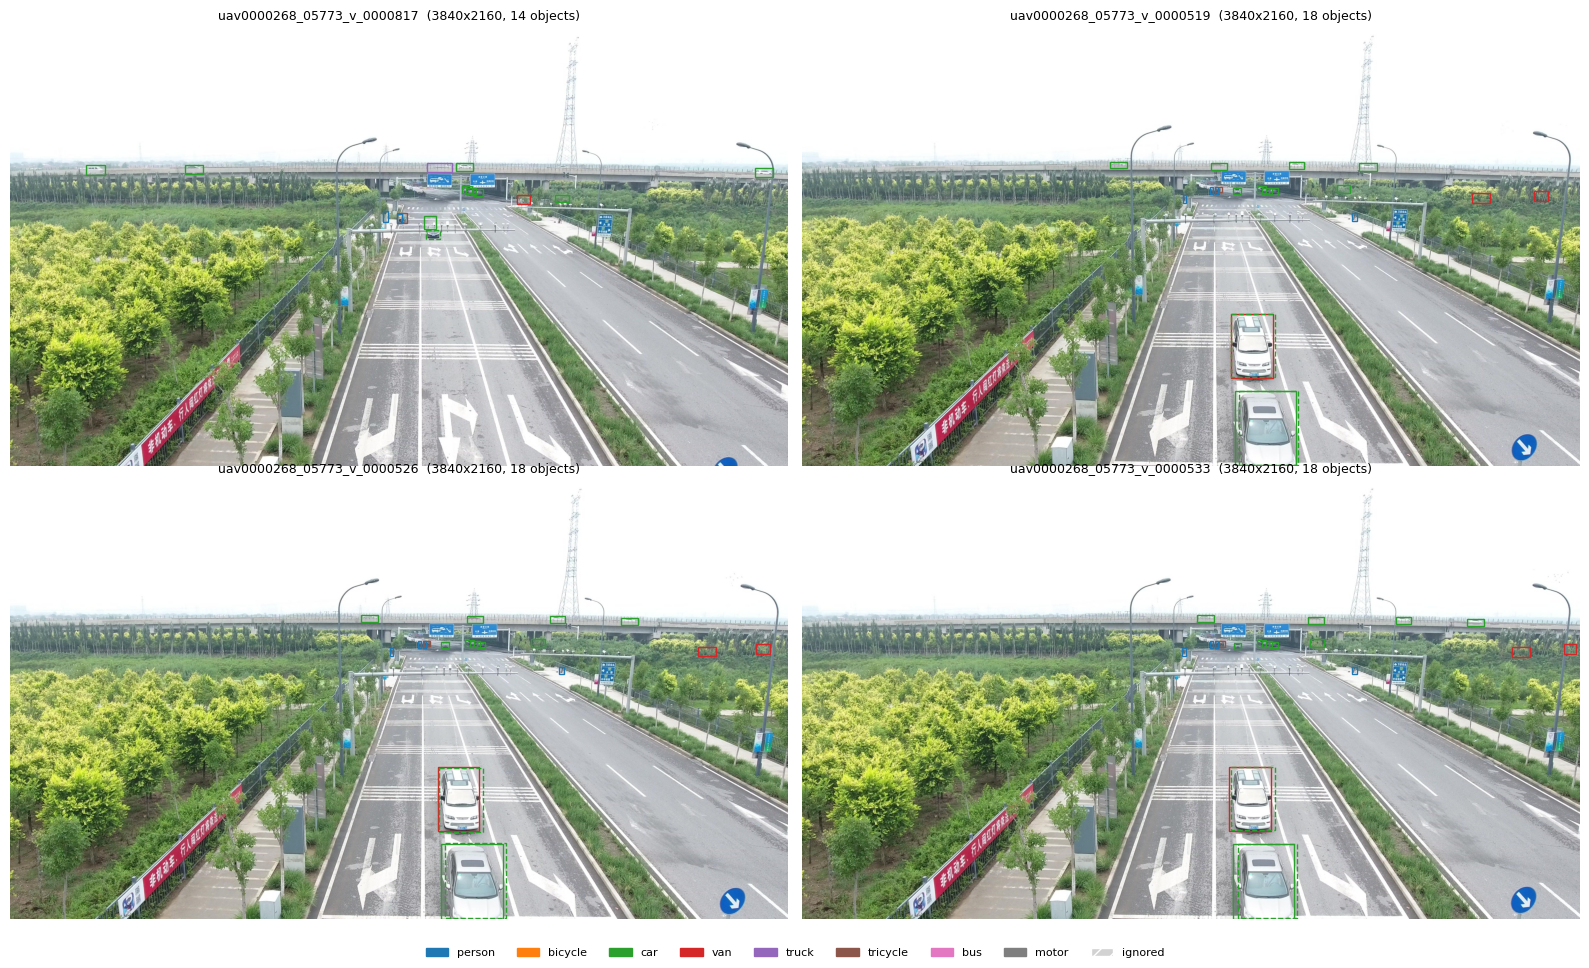

,0
count,150.000000
mean,0.527598
std,0.250432
min,0.000000
25%,0.250000
50%,0.609477
75%,0.718571
max,0.916667


In [13]:
BEST = res["mAP"].astype(float).idxmax()
preds = pd.read_csv(RUNS_DIR / BEST / "val_preds.csv.gz")
print("best experiment:", BEST)

# recall per frame at IoU 0.5 (score >= 0.3), to pick frames worth looking at
from vdet.data import box_iou_xywh
def frame_recall(k):
    g = val.boxes[val.boxes.key == k][["x", "y", "w", "h"]].to_numpy()
    p = preds[(preds.key == k) & (preds.score >= 0.3)][["x", "y", "w", "h"]].to_numpy()
    if len(g) == 0: return np.nan
    if len(p) == 0: return 0.0
    iou = np.array([box_iou_xywh(np.repeat(gi[None], len(p), 0), p).max() for gi in g])
    return (iou >= 0.5).mean()

sample = val.images.groupby("clip").head(1000).sample(min(150, len(val.images)), random_state=SEED).key
rec = pd.Series({k: frame_recall(k) for k in sample}).sort_values()
fig = V.show_frames(val, rec.index[:4].tolist(), preds=preds, score_thr=0.3, cols=2, size=8)
fig.savefig(FIG_DIR / "yolo_worst_frames.png", bbox_inches="tight"); plt.show()
rec.describe()

> **Observation.** All worst frames come from clip uav0000268 (3840×2160). At 1280 px this frame is downscaled 3×, so cars on the
> distant overpass become only a few pixels and are not detected (recall 0 on these frames). The near minivan is
> found but labelled car instead of van, the most common confusion. Over 150 sampled val frames the median recall
> (IoU 0.5, score ≥ 0.3) is 0.61, the mean 0.53.

## 6. Test predictions and submission (best experiment)

In [14]:
test = D.load_test_images(DATA_ROOT)
if SMOKE:
    test = test.groupby("clip").head(2)
model = YOLO(str(RUNS_DIR / BEST / "weights" / "best.pt"))
test_preds, sec = U.predict_table(model, test, imgsz=EXPERIMENTS[BEST]["imgsz"], batch=BATCH,
                                  half=DEVICE == 0, desc="test")
test_preds.to_csv(WORK_DIR / f"test_preds_yolo_{BEST}.csv.gz", index=False)
if not SMOKE:
    sub = S.write_submission(test_preds, DATA_ROOT, WORK_DIR / f"submission_yolo_{BEST}.csv")
    display(sub.head(3))
print(f"{len(test_preds)} detections on {test.key.nunique()} test frames, {sec*1000:.0f} ms/img")

test:   0%|          | 0/477 [00:00<?, ?it/s]

saved /content/drive/MyDrive/visdrone-work/submission_yolo_E1.csv: 3811 rows, 1340751 detections, 0 empty rows


,image_id,PredictionString
0,clip_001_0000001,0 0.7705 778.5 888.0 66.0 168.0 0 0.7656 633.0...
1,clip_001_0000002,0 0.7612 777.0 892.5 66.0 168.0 0 0.7529 627.8...
2,clip_001_0000003,0 0.8037 1668.0 796.5 60.0 153.0 0 0.7432 768....


1360071 detections on 3811 test frames, 29 ms/img


## 7. Summary

Higher resolution gave the largest gain (+7.4 mAP), mostly on small objects and thin classes. This follows from how
YOLOv8 assigns objects: candidates are grid points inside the box, and the task-aligned assigner keeps the top 10 by
score^0.5 · IoU^6. At 640 px a 10 px object covers about one stride-8 point, so it has almost no candidates and a poor
predicted IoU; at 1280 px it has four times more. The P2 head (stride 4) should give small objects even more points,
but with half of its weights untrained it did not pay off within 25 epochs. **E1 goes forward:** 19.8 mAP,
AP_small 12.7, 55 ms/img, public LB 0.2162.